# Assignment 1 on Colab

Runtime → Change runtime type → **T4 GPU** (free) or L4/A100 (Pro). Run the cells top to bottom. Everything that must survive a disconnect should be saved to Google Drive: data, checkpoints, results.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
WORK = '/content/drive/MyDrive/a1'
os.makedirs(WORK, exist_ok=True)
print(WORK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/a1


## 1. Code
Clone your repository (or upload the starter kit to Drive once and copy it here).

In [2]:
%cd /content
!git clone https://github.com/SaminaKadkhoda/DataMiningAssignements.git DataMiningAssignements        # TODO
%cd DataMiningAssignements/a1
!ls
!pip -q install regex einops jaxtyping pytest
import torch; print(torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no GPU')

/content
fatal: destination path 'DataMiningAssignements' already exists and is not an empty directory.
/content/DataMiningAssignements/a1
Assignment1.pdf  notebooks	 refrences.txt	scripts  uv.lock
lm		 pyproject.toml  report		tests
2.11.0+cu130 Tesla T4


In [12]:
#git pull for update in repo
%cd /content/DataMiningAssignements
!git pull

/content/DataMiningAssignements
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 5 (delta 2), reused 5 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 477 bytes | 477.00 KiB/s, done.
From https://github.com/SaminaKadkhoda/DataMiningAssignements
   beb598d..3dcae0f  main       -> origin/main
Updating beb598d..3dcae0f
Fast-forward
 a1/scripts/train.py | 5 +++--
 1 file changed, 3 insertions(+), 2 deletions(-)


## 2. Tests
They run on CPU in a few seconds. Fix failures before training anything.

In [1]:
#!python -m pytest -q tests/
%cd /content/DataMiningAssignements/a1
!python -m pytest -vv tests/test_data.py
!python -m pytest -vv tests/test_optimizer.py
!python -m pytest -vv tests/test_tokenizer.py
!python -m pytest -vv tests/test_nn_utils.py
!python -m pytest -vv tests/test_model.py

/content/DataMiningAssignements/a1
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/DataMiningAssignements/a1
configfile: pyproject.toml
plugins: jaxtyping-0.3.11, typeguard-4.6.0, anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4
collected 5 items                                                              

tests/test_data.py::test_get_batch_shapes_and_shift PASSED               [ 20%]
tests/test_data.py::test_get_batch_uses_the_whole_dataset PASSED         [ 40%]
tests/test_data.py::test_get_batch_from_memmap PASSED                    [ 60%]
tests/test_data.py::test_checkpoint_roundtrip_path PASSED                [ 80%]
tests/test_data.py::test_checkpoint_roundtrip_file_object PASSED         [100%]

============================== 5 passed in 0.18s ===============================
============================= test session start

## 3. Data
Download the TinyStories files once to Drive (links on Moodle), tokenise them with your tokenizer, then copy `train.bin`/`val.bin` to the local disk for speed at the start of every session.

In [8]:
!mkdir -p /content/data
!cp /content/drive/MyDrive/a1/data/*.bin /content/data/
!ls -lh /content/data

total 1.1G
-rw------- 1 root root 1.1G Oct 20 16:14 train.bin
-rw------- 1 root root  11M Oct 20 16:14 val.bin


In [9]:
# !wget -q -O $WORK/tinystories_train.txt <url>      # TODO, once (already downloaded)
#!python scripts/prepare_data.py --vocab $WORK/tok/vocab.json --merges $WORK/tok/merges.txt --input $WORK/tinystories_train.txt --output $WORK/train.bin (already done)
!mkdir -p /content/data && cp $WORK/*.bin /content/data/ 2>/dev/null; ls -la /content/data

total 1066928
drwxr-xr-x 2 root root       4096 Oct 20 16:14 .
drwxr-xr-x 1 root root       4096 Oct 20 16:14 ..
-rw------- 1 root root 1081594450 Oct 20 16:14 train.bin
-rw------- 1 root root   10922428 Oct 20 16:14 val.bin


## 4. Speed of this GPU (Lecture 2's script)

In [10]:
import torch, time
n, dt = 4096, torch.float16     # bf16 on L4/A100
a = torch.randn(n, n, device='cuda', dtype=dt); b = torch.randn(n, n, device='cuda', dtype=dt)
for _ in range(3): a @ b
torch.cuda.synchronize(); t = time.perf_counter()
for _ in range(20): c = a @ b
torch.cuda.synchronize(); sec = (time.perf_counter() - t) / 20
print(f'{2 * n**3 / sec / 1e12:.1f} TFLOP/s')

21.4 TFLOP/s


## 5. Train
Checkpoints go to Drive (`--out $WORK/runs/...`), so `--resume` continues after a disconnect. Do the resume test on a 200-step run before the reference run.

### a) full run on 200 step as a test

In [ ]:
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/smoke --steps 200 --eval_every 100 --ckpt_every 100

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:98: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.270365715026855, "lr": 0.0, "gnorm": 1.1741759777069092, "tokens_per_s": 7361.869802327148}
{"step": 0, "val_loss": 9.26521959900856}
{"step": 50, "loss": 3.9359796047210693, "lr": 0.0009051132292283772, "gnorm": 0.39072945713996887, "tokens_per_s": 8750.694588890425}
{"step": 100, "loss": 3.3685641288757324, "lr": 0.0005871607054625496, "gnorm": 0.42118385434150696, "tokens_per_s": 10861.267879646635}
{"step": 100, "val_loss": 3.3802997283637524}
{"step": 150, "loss": 3.257650852203369, "lr": 0.0002452232927684166, "gnorm": 0.42759469151496887, "tokens_per_s": 9572.363960227285}
{"step": 199, "val_loss": 3.078825967386365}
{"lr": 0.001, "steps": 200, "tok

In [ ]:
!ls -lh "$WORK/runs/smoke"

total 260M
-rw------- 1 root root 260M Oct 19 22:34 ckpt.pt
-rw------- 1 root root  404 Oct 19 22:31 config.json
-rw------- 1 root root  654 Oct 19 22:34 log.jsonl
-rw------- 1 root root  268 Oct 19 22:34 summary.json


### b) overfit-one-batch test

first training step with loss below 0.1: 25


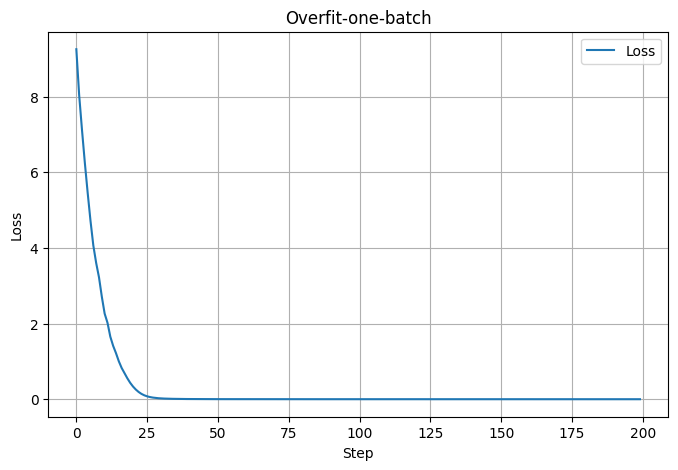

In [32]:
import json
import matplotlib.pyplot as plt
import numpy as np
from lm.model import TransformerLM, RotaryPositionalEmbedding
from lm.model_utils import cross_entropy, get_batch, AdamW

train_data = np.fromfile("/content/data/train.bin", dtype=np.uint16)
device = "cuda" #Tesla T4

model = TransformerLM(
    vocab_size=10000,
    context_length=256,
    d_model=512,
    num_layers=4,
    num_heads=16,
    num_kv_heads=16,
    d_ff=1344
).to(device)

optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)

def train_step():
    model.train()
    optimizer.zero_grad()
    logits = model(x)
    loss = cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    return loss.item()

x, y = get_batch(data = train_data, batch_size = 4, context_length = 256, device = device)
losses = [train_step() for step in range(200)]

first_step_below = None
for step, loss in enumerate(losses):
  if loss<0.1:
    first_step_below = step
    break
print(f"first training step with loss below 0.1: {first_step_below}")


plt.figure(figsize=(8, 5))
plt.plot([step for step in range(200)], [l for l in losses], label="Loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Overfit-one-batch")
plt.grid(True)
plt.legend()
plt.show()

### c) testing checkpoints by interupting a 200 step run and resuming it

In [ ]:
# kill the runtime here (Runtime → Interrupt) and rerun with --resume: the log must continue from the last checkpoint
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/resume --steps 200 --eval_every 100 --ckpt_every 100

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:98: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.270365715026855, "lr": 0.0, "gnorm": 1.1741759777069092, "tokens_per_s": 10382.728027565809}
{"step": 0, "val_loss": 9.26521959900856}
{"step": 50, "loss": 3.9359796047210693, "lr": 0.0009051132292283772, "gnorm": 0.39072945713996887, "tokens_per_s": 9387.740438689865}
{"step": 100, "loss": 3.3685641288757324, "lr": 0.0005871607054625496, "gnorm": 0.42118385434150696, "tokens_per_s": 11372.82855170486}
{"step": 100, "val_loss": 3.3802997283637524}
{"step": 150, "loss": 3.257650852203369, "lr": 0.0002452232927684166, "gnorm": 0.42759469151496887, "tokens_per_s": 10236.722919564114}
Traceback (most recent call last):
  File "/content/DataMiningAssignements/a

In [ ]:
#check if the checkpoint is stored
!ls -lh "$WORK/runs/resume"

total 260M
-rw-r--r-- 1 root root 260M Oct 19 23:03 ckpt.pt
-rw-r--r-- 1 root root  404 Oct 19 23:01 config.json
-rw-r--r-- 1 root root 1.5K Oct 19 23:03 log.jsonl


In [ ]:
#resuming from the chcekpoint wit --resume, the log continues from 101
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/resume --steps 200 --eval_every 100 --ckpt_every 100 --resume

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:98: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
resumed at step 101
{"step": 150, "loss": 3.0891945362091064, "lr": 0.0002452232927684166, "gnorm": 0.3939310312271118, "tokens_per_s": 14478.163883815407}
{"step": 199, "val_loss": 3.088463708758354}
{"lr": 0.001, "steps": 200, "tokens": 1638400, "flops": 183046137446400, "val_loss": 3.088463708758354, "tokens_per_s": 10705.42274569251, "mfu": 0.018400562305906774, "wallclock_s": 75.75674676895142, "gpu": "Tesla T4", "precision": "bfloat16"}


### d) Learning-rate sweep: chceking different lr rates, picking the best,  and plotting final validation loss

In [1]:
#sweep run: to find the best lr with lowest val_loss, i run four setups(i used torch.optim.AdamW(fused=True) and bf16 for faster runs)
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/rate3e4 --lr_max 3e-4 --steps 4883 --resume
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/rate1e3 --lr_max 1e-3 --steps 4883 --resume
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/rate3e3 --lr_max 3e-3 --steps 4883 --resume
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/rate1e2 --lr_max 1e-2 --steps 4883 --resume

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.270354270935059, "lr": 0.0, "gnorm": 1.1744587421417236, "tokens_per_s": 13413.708855496638}
{"step": 0, "val_loss": 9.26521959900856}
{"step": 50, "loss": 7.773087024688721, "lr": 6.147540983606557e-05, "gnorm": 2.356729030609131, "tokens_per_s": 12283.986347031314}
{"step": 100, "loss": 5.463321685791016, "lr": 0.00012295081967213115, "gnorm": 1.2287797927856445, "tokens_per_s": 17530.864073335943}
{"step": 150, "loss": 4.346462249755859, "lr": 0.00018442622950819672, "gnorm": 0.48724791407585144, "tokens_per_s": 20612.175718876635}
{"step": 200, "loss": 3.791764736175537, "lr": 0.0002459016393442623, "gnorm": 0.5039934515953064, "tokens_per_s": 22655.4

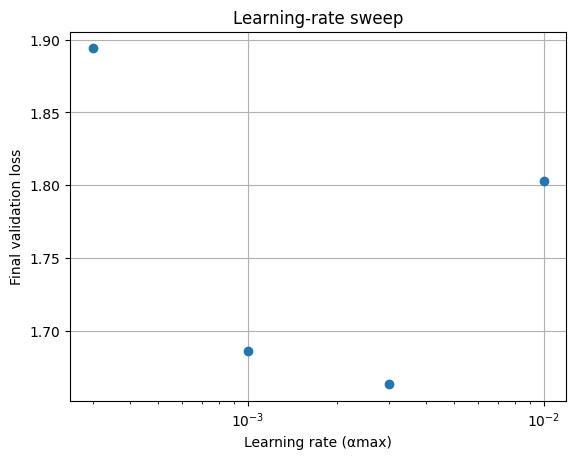

In [22]:
import matplotlib.pyplot as plt

final_vals = {
    3e-4: 1.894000856205821,
    1e-3: 1.6860599108040333,
    3e-3: 1.6630598399788141, #best rate
    1e-2: 1.8029726967215538,
}

plt.plot(list(final_vals.keys()), list(final_vals.values()), "o")
plt.xscale("log")
plt.xlabel("Learning rate (αmax)")
plt.ylabel("Final validation loss")
plt.title("Learning-rate sweep")
plt.grid(True)
plt.show()

### e) One ablation: running the same sweep run with the best lr rate and no warmup (--warmup_frac 0)

In [16]:
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/ablation_no_warmup --lr_max 3e-3 --steps 4883 --warmup_frac 0.0

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.270354270935059, "lr": 0.003, "gnorm": 1.1744587421417236, "tokens_per_s": 13290.503123640141}
{"step": 0, "val_loss": 8.308622233569622}
{"step": 50, "loss": 4.014072418212891, "lr": 0.002999301554334516, "gnorm": 0.48403698205947876, "tokens_per_s": 14134.395321679238}
{"step": 100, "loss": 3.4532346725463867, "lr": 0.002997206940043765, "gnorm": 0.4219081699848175, "tokens_per_s": 19769.721039749544}
{"step": 150, "loss": 3.306354522705078, "lr": 0.0029937183244970393, "gnorm": 0.37734755873680115, "tokens_per_s": 22804.905904159918}
{"step": 200, "loss": 3.054483652114868, "lr": 0.002988839317484571, "gnorm": 0.33483394980430603, "tokens_per_s": 24663

### f) Reference run: running full steps with the best lr rate

In [17]:
# the reference run (Table 1 of the handout); 30-60 min on a T4
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/ref --lr_max 3e-3 --steps 24414 --resume

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
{"step": 0, "loss": 9.270354270935059, "lr": 0.0, "gnorm": 1.1744587421417236, "tokens_per_s": 13591.319197884548}
{"step": 0, "val_loss": 9.26521959900856}
{"step": 50, "loss": 6.910492897033691, "lr": 0.00012295081967213115, "gnorm": 2.2186150550842285, "tokens_per_s": 14231.102325479522}
{"step": 100, "loss": 4.494437217712402, "lr": 0.0002459016393442623, "gnorm": 0.5268807411193848, "tokens_per_s": 19875.84970779639}
{"step": 150, "loss": 3.813246250152588, "lr": 0.00036885245901639344, "gnorm": 0.4472523629665375, "tokens_per_s": 22926.684935743186}
{"step": 200, "loss": 3.370018243789673, "lr": 0.0004918032786885246, "gnorm": 0.5219364166259766, "tokens_per_s": 24805.33

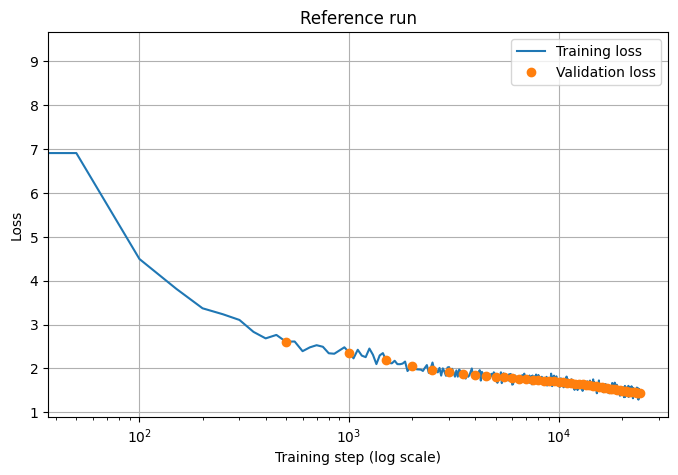

In [21]:
import json
from pathlib import Path
import matplotlib.pyplot as plt

run_dir = Path(WORK) / "runs" / "ref"

with open(run_dir / "log.jsonl") as f:
    records = [json.loads(line) for line in f if line.strip()]

train = [r for r in records if "loss" in r]
val = [r for r in records if "val_loss" in r]

plt.figure(figsize=(8, 5))
plt.plot([r["step"] for r in train], [r["loss"] for r in train], label="Training loss")
plt.plot([r["step"] for r in val], [r["val_loss"] for r in val], "o", label="Validation loss")
plt.xscale("log")
plt.xlabel("Training step (log scale)")
plt.ylabel("Loss")
plt.title("Reference run")
plt.grid(True)
plt.legend()
plt.show()

In [20]:
with open(run_dir / "summary.json") as f:
    summary = json.load(f)

print("Final validation loss:", summary["val_loss"])
print("GPU:", summary["gpu"])
print("tokens/s:", summary["tokens_per_s"])
print("MFU:", summary["mfu"])

Final validation loss: 1.4422505274415016
GPU: Tesla T4
tokens/s: 27362.148836421435
MFU: 0.047030270214284596


### g) Efficiency table: running

In [5]:
#Eager fp32 baseline
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/efficiency_eager_fp32 --lr_max 3e-3 --steps 260


/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:106: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=False) #for eager fp32
eager 200-step tokens_per_s: 17665.10116038851
/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
----------

In [7]:
#autocast fp16 or bf16
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/efficiency_autocast --lr_max 3e-3 --steps 260


/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
autocast 200-step tokens_per_s: 33317.15464290594
/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time

In [9]:
#F.sdpa
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/efficiency_sdpa --lr_max 3e-3 --steps 260

/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
F.sdpa 200-step tokens_per_s: 54434.21741950837
/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time a

In [11]:
#torch.optim.AdamW(fused=True)
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/efficiency_adamw --lr_max 3e-3 --steps 260


/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
torch.optim.AdamW 200-step tokens_per_s: 58578.47984669711
/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  

In [13]:
#torch.compile
%cd /content/DataMiningAssignements/a1
!PYTHONPATH=. python scripts/train.py --data /content/data/train.bin --val /content/data/val.bin --out $WORK/runs/efficiency_compile --lr_max 3e-3 --steps 260


/content/DataMiningAssignements/a1
/content/DataMiningAssignements/a1/scripts/train.py:103: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda" and amp_dtype == torch.float16))
torch.compile 200-step tokens_per_s: 85241.8108361401
/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA 

### h) samples

In [20]:
!ls -lh "$WORK/runs/ref"
!cat "$WORK/runs/ref/config.json"
!ls -lh /content/data/

total 260M
-rw------- 1 root root 260M Oct 20 13:13 ckpt.pt
-rw------- 1 root root  407 Oct 20 11:11 config.json
-rw------- 1 root root  68K Oct 20 11:11 log.jsonl
-rw------- 1 root root  274 Oct 20 13:13 summary.json
{
  "vocab_size": 10000,
  "context_length": 256,
  "d_model": 512,
  "num_layers": 4,
  "num_heads": 16,
  "d_ff": 1344,
  "rope_theta": 10000.0,
  "batch_size": 32,
  "steps": 24414,
  "lr_max": 0.003,
  "lr_min_frac": 0.1,
  "warmup_frac": 0.05,
  "weight_decay": 0.1,
  "beta1": 0.9,
  "beta2": 0.95,
  "grad_clip": 1.0,
  "eval_every": 500,
  "eval_tokens": 1048576,
  "ckpt_every": 1000,
  "seed": 0
}total 1.1G
-rw------- 1 root root 1.1G Oct 20 16:14 train.bin
-rw------- 1 root root  11M Oct 20 16:14 val.bin


In [21]:
!find /content/drive/MyDrive/a1 /content/DataMiningAssignements/a1 -type f | grep -Ei 'vocab|merges'

/content/drive/MyDrive/a1/data/merges_train.json
/content/drive/MyDrive/a1/data/vocab_train.json


In [23]:
from lm.tokenizer import Tokenizer
from lm.model_utils import generate
from lm.model import TransformerLM, RotaryPositionalEmbedding
import json
import torch

device = "cuda"
with open("/content/drive/MyDrive/a1/runs/ref/config.json") as f: #using the config of ref run
    cfg = json.load(f)

rope = RotaryPositionalEmbedding(theta=cfg["rope_theta"], d_k=cfg["d_model"] // cfg["num_heads"], max_seq_len=cfg["context_length"])

model = TransformerLM(vocab_size=cfg["vocab_size"], context_length=cfg["context_length"], d_model=cfg["d_model"],
                      num_layers=cfg["num_layers"], num_heads=cfg["num_heads"], d_ff=cfg["d_ff"], rope=rope).to(device)

checkpoint = torch.load("/content/drive/MyDrive/a1/runs/ref/ckpt.pt", map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model"])
model.eval()
print(f"checkpoint from step {checkpoint["step"]}")

special_tokens = ["<|endoftext|>"]
tokenizer = Tokenizer.from_files("/content/drive/MyDrive/a1/data/vocab_train.json", "/content/drive/MyDrive/a1/data/merges_train.json", special_tokens=special_tokens)
prompts = ["Today the weather is sunny and the trees are tall",
           "Harry answered the phone call and talked to his mother for four minutes.",
           "The quantum computing center in London collaborates with industry to develop infrastructure.",
           "The friendly waitress took the orders from a few tables and brought them to the kitchen.",
           "She decided to study history of art to work in the most famous gallery and teach kids.",
           "Planet Jupiter is the biggest planet in our solar system and it's brown and white."]
prompt_ids = []
for p in prompts:
   prompt_ids.append(tokenizer.encode(p))

for i in range(5):
  generated_ids = generate(model, prompt_ids[i], max_new_tokens=256, temperature=0.7, top_p=0.9, eos_id=tokenizer.special["<|endoftext|>"])
  continuation = tokenizer.decode(generated_ids)
  print(prompts[i] + continuation)

generated_ids = generate(model, prompt_ids[5], max_new_tokens=256, temperature=1.5, top_p=0.9, eos_id=tokenizer.special["<|endoftext|>"])
continuation = tokenizer.decode(generated_ids)
print(prompts[5] + continuation)

checkpoint from step 24414
Today the weather is sunny and the trees are tall. They are happy and warm. They play outside in the sun. They have fun.
<|endoftext|>
Harry answered the phone call and talked to his mother for four minutes. His mother was very impressed with how the phone made such a special voice. She was proud of him and his mother was very proud of him.
<|endoftext|>
The quantum computing center in London collaborates with industry to develop infrastructure. L sends another message that said, "Losties. We must find a way to get them to be healthy. We need to find a way to help them."
L weighedpted to find a way to make Lions feel better, but the message was too much. In the end, Lae was sad and she wished she had listened to her mom.
The next day, Lyan's mom saw her sad face and asked her what was wrong. L� told her about the message and she said, "I'm sorry Lrm NAvon. I'm sorry, Lowly. I need to learn to be healthy again."
L bluebird smiled and said, "It's okay, Lpril. I

### i) Profiler

In [15]:
from torch.profiler import profile, ProfilerActivity
import json
import numpy as np
from lm.model import TransformerLM, RotaryPositionalEmbedding
from lm.model_utils import cross_entropy, get_batch, AdamW

train_data = np.fromfile("/content/data/train.bin", dtype=np.uint16)
device = "cuda" #Tesla T4

model = TransformerLM(
    vocab_size=10000,
    context_length=256,
    d_model=512,
    num_layers=4,
    num_heads=16,
    num_kv_heads=16,
    d_ff=1344
).to(device)

optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)

def train_step():
    model.train()
    optimizer.zero_grad()
    logits = model(x)
    loss = cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    return loss.item()

x, y = get_batch(data = train_data, batch_size = 4, context_length = 256, device = device)

for _ in range(3): #warmup
    train_step()

torch.cuda.synchronize()
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
    for _ in range(5):
        train_step()
    torch.cuda.synchronize()

print(prof.key_averages().table(sort_by="cuda_time_total", row_limit=20))
prof.export_chrome_trace("/content/drive/MyDrive/a1/trace.json")

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                              aten::bmm         6.06%      18.403ms         8.91%      27.074ms      62.240us     110.059ms        41.54%     110.059ms     253.010us           435  
                              Optimizer.step#AdamW.step         0.00%       0.000us         0.00%       0.000us       0.000us      87.989ms        33.21%      87.989ms      17.598ms             5  
      aut

## 6. results.json
Assemble it from the run summaries and check it before submitting.

In [25]:
!ls -lh "$WORK/runs"

total 52K
drwx------ 2 root root 4.0K Oct 20 10:17 ablation_no_warmup
drwx------ 2 root root 4.0K Oct 20 19:09 efficiency_adamw
drwx------ 2 root root 4.0K Oct 20 18:53 efficiency_autocast
drwx------ 2 root root 4.0K Oct 20 19:11 efficiency_compile
drwx------ 2 root root 4.0K Oct 20 18:41 efficiency_eager_fp32
drwx------ 2 root root 4.0K Oct 20 19:00 efficiency_sdpa
drwx------ 2 root root 4.0K Oct 20 08:26 rate1e2
drwx------ 2 root root 4.0K Oct 20 08:25 rate1e3
drwx------ 2 root root 4.0K Oct 20 08:26 rate3e3
drwx------ 2 root root 4.0K Oct 20 07:54 rate3e4
drwx------ 2 root root 4.0K Oct 20 11:11 ref
drwx------ 2 root root 4.0K Oct 19 22:41 resume
drwx------ 2 root root 4.0K Oct 19 22:31 smoke


In [31]:
from pathlib import Path
import json

runs_dir = Path("/content/drive/MyDrive/a1/runs")
run_names = [ #these runs had no summries(sweeps), so added info manually from logs: "rate1e2", "rate1e3", "rate3e3", "rate3e4"
    "ref", "ablation_no_warmup",
    "efficiency_eager_fp32", "efficiency_autocast",
    "efficiency_sdpa", "efficiency_adamw", "efficiency_compile", "smoke"
]

efficiency_tps = {
    "efficiency_eager_fp32": 17665.10116038851,
    "efficiency_autocast": 33317.15464290594,
    "efficiency_sdpa": 54434.21741950837,
    "efficiency_adamw": 58578.47984669711,
    "efficiency_compile": 85241.8108361401,
}

results = []
for name in run_names:
    with open(runs_dir / name / "summary.json") as f:
        summary = json.load(f)

    results.append({
        "run": name,
        "lr": summary["lr"],
        "steps": summary["steps"],
        "tokens": summary["tokens"],
        "val_loss": summary["val_loss"],
        "tokens_per_s": efficiency_tps.get(name, summary["tokens_per_s"]),
    })

with open("/content/drive/MyDrive/a1/results.json", "w") as f:
    json.dump(results, f, indent=2)

In [18]:
!python grading/validate_results.py $WORK/results.json

python3: can't open file '/content/DataMiningAssignements/a1/grading/validate_results.py': [Errno 2] No such file or directory
